In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
target = "tip"

print("Target variable:", target)
print("Data type:", df[target].dtype)
print("Missing values:", df[target].isnull().sum())
print("Unique values:", df[target].nunique())

Target variable: tip
Data type: float64
Missing values: 0
Unique values: 123


## 1. Introduction to Target Variable Analysis

A target variable is the variable a machine learning model attempts to predict. Target variable analysis helps us understand its distribution, data quality, variability, and suitability for a machine learning task.

In this notebook, `tip` is used as a regression target because it is numerical. A separate categorical example will be used to demonstrate classification concepts.

## 2. Regression Target Distribution

In regression, the target variable is numerical. Analyzing its distribution helps identify the typical range of values, skewness, spread, and potential outliers before model training.

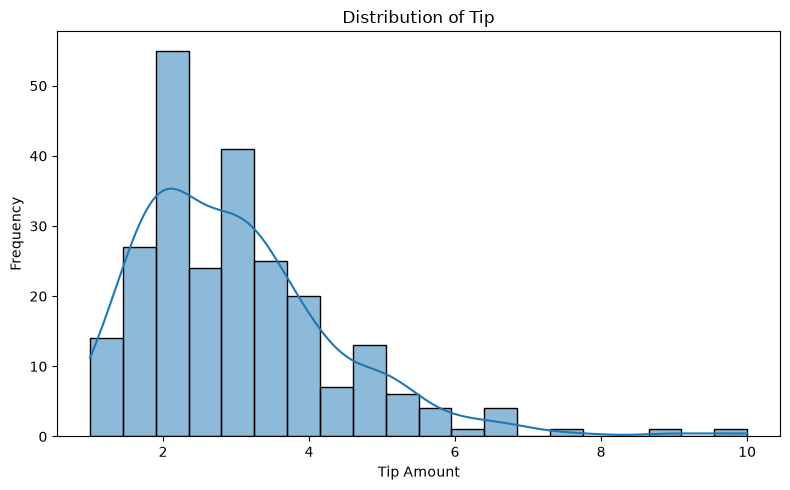

In [3]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tip", kde=True, bins=20)

plt.title("Distribution of Tip")
plt.xlabel("Tip Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [4]:
target_series = df["tip"].dropna()

print("Mean:", round(target_series.mean(), 3))
print("Median:", round(target_series.median(), 3))
print("Variance:", round(target_series.var(), 3))
print("Standard Deviation:", round(target_series.std(), 3))
print("Skewness:", round(target_series.skew(), 3))

Mean: 2.998
Median: 2.9
Variance: 1.914
Standard Deviation: 1.384
Skewness: 1.465


In [6]:
# Analyze outliers in the target variable
target_series = df["tip"].dropna()

Q1 = target_series.quantile(0.25)
Q3 = target_series.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = target_series[
    (target_series < lower_bound) |
    (target_series > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))

display(outliers.to_frame(name="Potential Outlier"))

Lower bound: -0.34
Upper bound: 5.91
Potential outliers: 9


,Potential Outlier
23,7.58
47,6.00
59,6.73
141,6.70
170,10.00
183,6.50
212,9.00
214,6.50
239,5.92


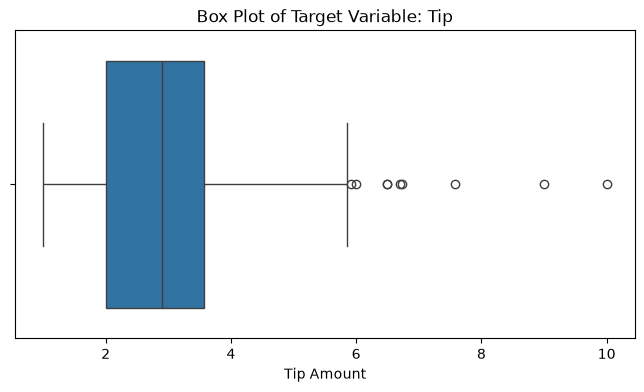

In [7]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["tip"])
plt.title("Box Plot of Target Variable: Tip")
plt.xlabel("Tip Amount")
plt.show()

## 3. Classification Target Analysis

In classification, the target variable represents categories or classes. Analyzing class counts and percentages helps us understand whether classes are evenly distributed or whether some classes are underrepresented.

In [8]:
classification_target = "smoker"

class_counts = df[classification_target].value_counts(dropna=False)

print("Class Counts:")
display(class_counts.to_frame(name="Count"))

print("\nClass Distribution:")
display(
    df[classification_target]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
    .to_frame(name="Percentage")
)

Class Counts:


,Count
smoker,
No,151
Yes,93



Class Distribution:


,Percentage
smoker,
No,61.89
Yes,38.11


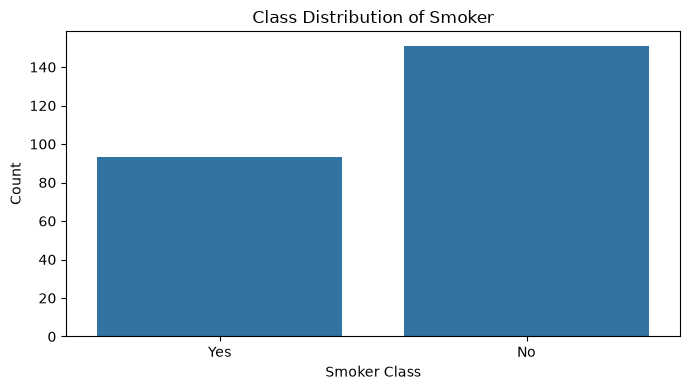

In [9]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x=classification_target)

plt.title("Class Distribution of Smoker")
plt.xlabel("Smoker Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [10]:
valid_counts = df[classification_target].value_counts()

imbalance_ratio = valid_counts.max() / valid_counts.min()

print("Largest class count:", valid_counts.max())
print("Smallest class count:", valid_counts.min())
print("Class imbalance ratio:", round(imbalance_ratio, 2))

Largest class count: 151
Smallest class count: 93
Class imbalance ratio: 1.62


In [11]:
# Regression target summary
target_series = df["tip"].dropna()

target_summary = pd.DataFrame({
    "Metric": [
        "Count",
        "Mean",
        "Median",
        "Variance",
        "Standard Deviation",
        "Skewness",
        "Minimum",
        "Maximum"
    ],
    "Value": [
        target_series.count(),
        target_series.mean(),
        target_series.median(),
        target_series.var(),
        target_series.std(),
        target_series.skew(),
        target_series.min(),
        target_series.max()
    ]
})

display(target_summary.round(3))

,Metric,Value
0,Count,244.000
1,Mean,2.998
2,Median,2.900
3,Variance,1.914
4,Standard Deviation,1.384
5,Skewness,1.465
6,Minimum,1.000
7,Maximum,10.000


## 4. Target Variable Interpretation

The `tip` column is treated as the regression target because it contains numerical values. Its mean and median describe the center of the distribution, while variance and standard deviation measure its spread. Skewness indicates whether the distribution is asymmetric, and the box plot helps identify potential outliers.

The `smoker` column is used as a separate classification example. Class counts, percentages, and a class imbalance ratio help describe how observations are distributed between categories.

These results are useful for selecting appropriate preprocessing and evaluation methods before building a machine learning model.

## Conclusion

In this notebook, I analyzed a numerical regression target and a categorical classification target. For the regression target, I examined its distribution, mean, median, variance, standard deviation, skewness, and potential outliers using descriptive statistics and a box plot. For the classification target, I calculated class counts, percentages, and an imbalance ratio and visualized the class distribution.

Understanding the target variable before machine learning helps identify data-quality issues, understand the prediction problem, choose suitable preprocessing techniques, and select appropriate evaluation metrics. Potential outliers and class imbalance should be investigated rather than automatically corrected or removed.